# 04 - Data preparation for Ultralytics detectors (YOLO, RT-DETR)

This notebook documents the preprocessing used by the anchor-free and query-based experiments.
The dataset itself is built by `scripts/prepare_data.py`; here we justify and verify its choices:

1. sequence-level folds identical to the team manifest used for Faster R-CNN and RetinaNet;
2. the frame sampling step;
3. masking of ignored regions;
4. correctness of label conversion and of the evaluator.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.common import CLASS_NAMES, WORK_DIR, find_data_root
from src.data import boxes_by_image, images_table, load_coco, make_folds, mask_ignored, sample_frames
from src.evaluate import coco_evaluate, format_metrics

DATA_ROOT = find_data_root()

## 1. Sequence-level folds

Frames of one clip are strongly correlated, so every clip belongs to exactly one fold.
`GroupKFold(n_splits=3)` grouped by clip is deterministic and reproduces the team manifest
(held-out sizes 8080 / 8082 / 8039 frames), so all detector families share the same splits.
Tuning experiments fit on folds 1-2 and are evaluated on fold 0; the supplied `val` split
is kept as an independent check of the selected configurations.

In [2]:
train = make_folds(images_table("train"))
val = images_table("val")

fold_table = train.groupby("fold").agg(holdout_clips=("video", "nunique"), holdout_frames=("image_id", "size"))
fold_table["fit_frames"] = len(train) - fold_table["holdout_frames"]
assert fold_table["holdout_frames"].tolist() == [8080, 8082, 8039]
assert train.groupby("video")["fold"].nunique().max() == 1
fold_table

,holdout_clips,holdout_frames,fit_frames
fold,,,
0,19,8080,16121
1,19,8082,16119
2,18,8039,16162


## 2. Frame sampling step

We measure how much a scene changes between frames: for every tracked object (`track_id`)
we compute the IoU of its box at frame `t` and at frame `t + k`. High IoU means the frame
adds almost no new information.

In [3]:
coco = load_coco("train")
frame_of = {img["id"]: (img["video"], img["frame_id"]) for img in coco["images"]}

rows = []
for ann in coco["annotations"]:
    if ann["iscrowd"]:
        continue
    video, frame = frame_of[ann["image_id"]]
    x, y, w, h = ann["bbox"]
    rows.append((video, ann["track_id"], frame, x, y, x + w, y + h))
tracks = pd.DataFrame(rows, columns=["video", "track_id", "frame_id", "x1", "y1", "x2", "y2"])


def track_iou(tracks, step):
    shifted = tracks.assign(frame_id=tracks["frame_id"] + step)
    pairs = tracks.merge(shifted, on=["video", "track_id", "frame_id"], suffixes=("", "_p"))
    inter_w = (np.minimum(pairs.x2, pairs.x2_p) - np.maximum(pairs.x1, pairs.x1_p)).clip(0)
    inter_h = (np.minimum(pairs.y2, pairs.y2_p) - np.maximum(pairs.y1, pairs.y1_p)).clip(0)
    inter = inter_w * inter_h
    area = (pairs.x2 - pairs.x1) * (pairs.y2 - pairs.y1)
    area_p = (pairs.x2_p - pairs.x1_p) * (pairs.y2_p - pairs.y1_p)
    return inter / (area + area_p - inter)


steps = [1, 2, 3, 5, 10, 20]
step_table = pd.DataFrame(
    [{"step": k, "median_iou": track_iou(tracks, k).median(), "share_iou_gt_0.5": (track_iou(tracks, k) > 0.5).mean()}
     for k in steps]
).set_index("step")
step_table["fold0_fit_frames"] = [len(sample_frames(train[train["fold"] != 0], k)) for k in steps]
step_table.round(3)

,median_iou,share_iou_gt_0.5,fold0_fit_frames
step,,,
1,0.897,0.959,16121
2,0.810,0.860,8070
3,0.731,0.755,5388
5,0.597,0.594,3243
10,0.357,0.393,1629
20,0.102,0.261,824


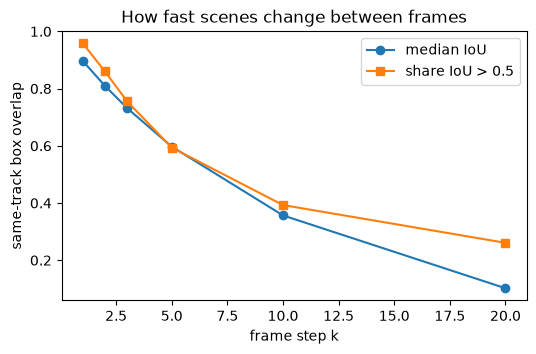

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(step_table.index, step_table["median_iou"], marker="o", label="median IoU")
ax.plot(step_table.index, step_table["share_iou_gt_0.5"], marker="s", label="share IoU > 0.5")
ax.set_xlabel("frame step k")
ax.set_ylabel("same-track box overlap")
ax.set_title("How fast scenes change between frames")
ax.legend()
plt.show()

**Choice.** Consecutive frames are near duplicates (median IoU 0.90), while at step 10
the median IoU drops to about 0.36, so the sampled frames show objects in clearly different
positions. Tuning runs use **step 10** (1629 training frames for fold 0) to fit several
experiments into the GPU budget of a single laptop GPU; the final model may use a smaller
step (more data) once the configuration is fixed.

Evaluation subsets are fixed for all experiments: every 10th frame of the fold-0 holdout
(817 frames) and every 5th frame of `val` (571 frames). Every frame of every clip is
eligible, and sampling always starts at the first frame of a clip, so it is reproducible.

## 3. Ignored regions

Ignored regions (crowds, parking lots, VisDrone "others") contain unlabelled objects.
Ultralytics has no notion of ignore areas, so leaving them visible would teach the model
that real cars and people there are background. We fill them with gray (114, the same
value Ultralytics uses for letterbox padding) and then paste back the pixels of labelled
boxes, so no target is erased even when it overlaps an ignored region.

Masking is applied only to training images (and the per-epoch curve images). The official
metric is computed on the original frames, where ignored regions are `iscrowd=1`
annotations and detections inside them are not penalised.

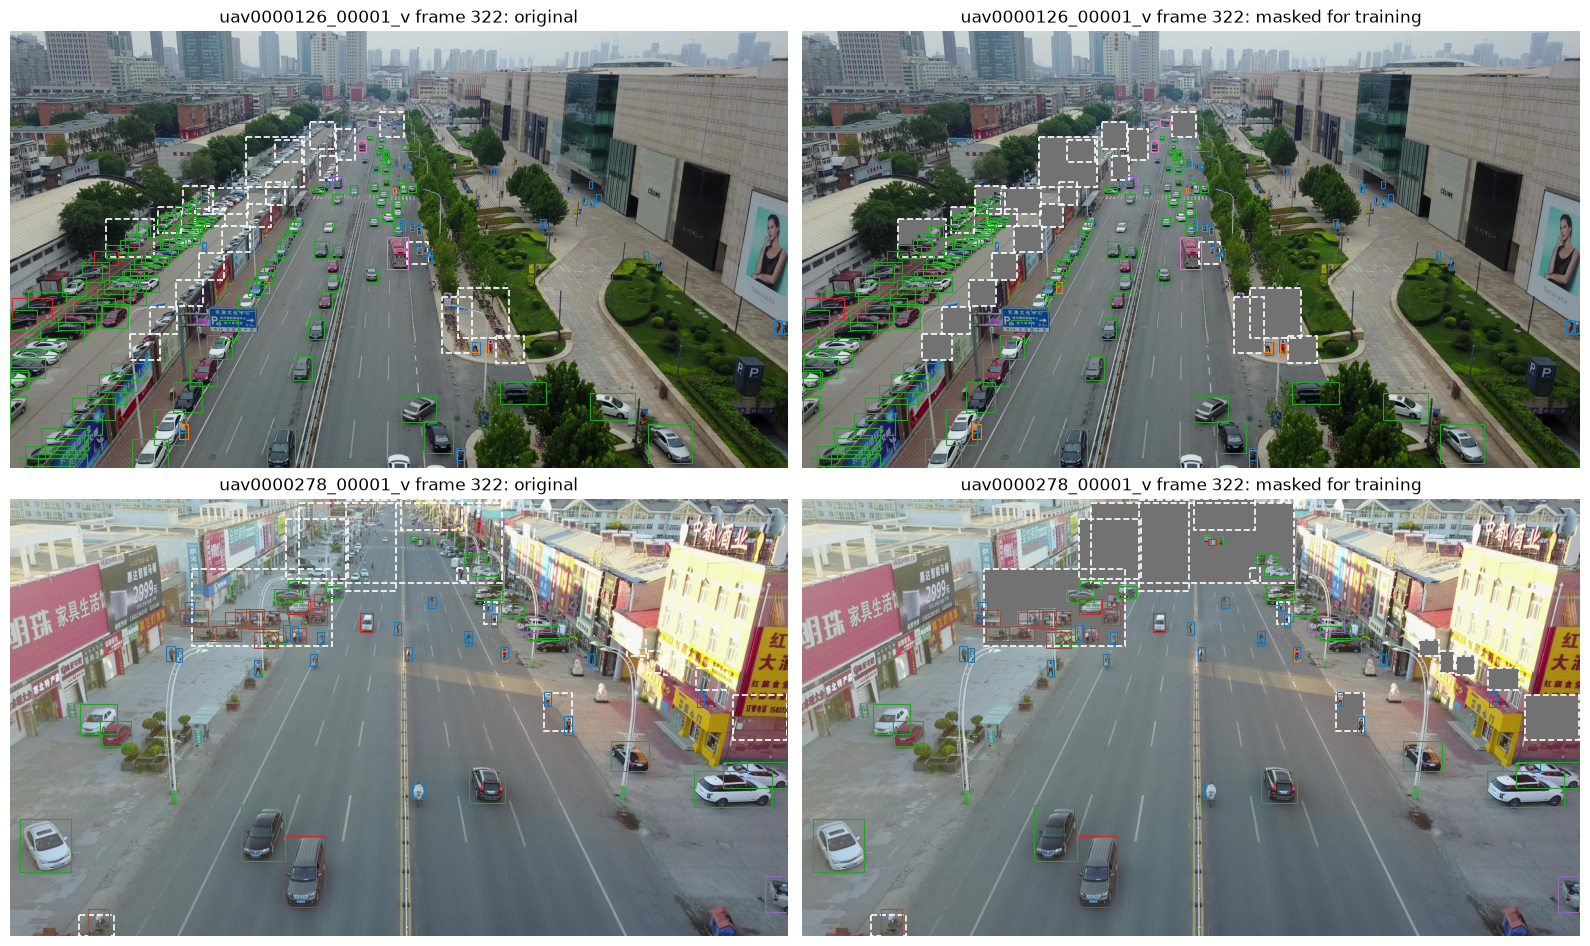

In [5]:
targets, ignored = boxes_by_image("train")
frames = train.set_index("image_id")

# Frames with the most ignored regions, taken from two different clips
counts = pd.DataFrame({"image_id": list(ignored), "n_ignored": [len(v) for v in ignored.values()]})
counts["video"] = frames.loc[counts["image_id"], "video"].to_numpy()
examples = counts.sort_values("n_ignored", ascending=False).drop_duplicates("video")["image_id"].head(2).tolist()

colors = plt.cm.tab10(np.arange(len(CLASS_NAMES)))
fig, axes = plt.subplots(len(examples), 2, figsize=(16, 4.8 * len(examples)))
for row, image_id in zip(axes, examples):
    info = frames.loc[image_id]
    image = cv2.imread(str(DATA_ROOT / "train" / info.file_name))[:, :, ::-1]
    masked = mask_ignored(image, ignored[image_id], targets.get(image_id, np.zeros((0, 5))))
    for ax, img, title in zip(row, [image, masked], ["original", "masked for training"]):
        ax.imshow(img)
        for x1, y1, x2, y2 in ignored[image_id]:
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="white", ls="--", lw=1.2))
        for cls, x1, y1, x2, y2 in targets.get(image_id, []):
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=colors[int(cls)], lw=0.8))
        ax.set_title(f"{info.video} frame {info.frame_id}: {title}")
        ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Verification of the conversion and of the evaluator

Labels are rebuilt from the COCO file, so we compare them against the YOLO labels shipped
with the competition. Then we pass the ground truth itself as predictions: the evaluator must
return AP = 1, and extra detections placed on ignored regions must not reduce it.

In [6]:
yolo_dir = WORK_DIR / "yolo" / "fold0_s10"
mismatches, checked = 0, 0
for label_path in sorted((yolo_dir / "labels" / "train").glob("*.txt")):
    video, frame = label_path.stem.rsplit("_", 1)
    ours = np.loadtxt(label_path, ndmin=2)
    reference = np.loadtxt(DATA_ROOT / "train" / "labels" / video / f"{frame}.txt", ndmin=2)
    checked += 1
    if ours.shape != reference.shape or np.abs(np.sort(ours, 0) - np.sort(reference, 0)).max() > 1e-4:
        mismatches += 1
print(f"label files checked: {checked}, mismatches: {mismatches}")

label files checked: 1629, mismatches: 0


In [7]:
gt_path = WORK_DIR / "eval" / "fold0_holdout.json"
gt = json.loads(gt_path.read_text())

perfect = [dict(image_id=a["image_id"], category_id=a["category_id"], bbox=a["bbox"], score=1.0)
           for a in gt["annotations"] if not a["iscrowd"]]
on_ignored = [dict(image_id=a["image_id"], category_id=a["category_id"], bbox=a["bbox"], score=0.5)
              for a in gt["annotations"] if a["iscrowd"]]

print("ground truth as predictions:   ", format_metrics(coco_evaluate(gt_path, perfect)))
print("plus detections on ignored areas:", format_metrics(coco_evaluate(gt_path, perfect + on_ignored)))

ground truth as predictions:    AP=1.0000  AP50=1.0000  AP75=1.0000  AP_small=1.0000  AP_medium=1.0000  AP_large=1.0000


plus detections on ignored areas: AP=1.0000  AP50=1.0000  AP75=1.0000  AP_small=1.0000  AP_medium=1.0000  AP_large=1.0000


## 5. Summary of the protocol

| Item | Setting |
|---|---|
| Folds | GroupKFold(3) by clip, identical to the team manifest; tuning on fold 0 |
| Training frames | every 10th frame of folds 1-2 (1629 frames) |
| Evaluation | every 10th frame of fold 0 (817) and every 5th frame of val (571), original images |
| Ignored regions | masked with gray in training images, `iscrowd=1` in evaluation |
| Metric | COCO mAP@[.5:.95], AP50, AP_small, up to 500 detections per image (as on Kaggle) |
| Classes | 8 classes, YOLO ids 0-7, COCO ids 1-8 |